# TP1 PROCESAMIENTO DEL HABLA — Web Scraping y Preprocesamiento

**Alumno:** Agustín Delgado

Para este trabajo elegí una entrevista en español a Marvin Minsky, uno de los pioneros de la inteligencia artificial. La entrevista trata temas relacionados con el funcionamiento de la mente, el aprendizaje, la inteligencia artificial y las emociones.

**Página utilizada para el web scraping:**  
https://indecquetrabajaiii.blogspot.com/2016/02/genios-contemporaneos-marvin-minsky.html

El objetivo de mi trabajo es extraer el texto de una única página web y aplicar las distintas etapas de preprocesamiento pedidas en la consigna.

## 0 - Instalación e importación de librerías

En este primer punto instalo e importo las librerías que voy a utilizar para descargar la página, procesar el HTML, trabajar con el texto, generar la nube de palabras y construir las matrices.

In [1]:
!pip install -q beautifulsoup4 wordcloud nltk scikit-learn

import re
import requests
import nltk
import pandas as pd
import matplotlib.pyplot as plt

from bs4 import BeautifulSoup
from nltk.corpus import stopwords
from nltk.tokenize import sent_tokenize
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer

nltk.download("stopwords", quiet=True)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 1 - Web scraping

En este punto realizo el web scraping. Primero descargo la página con `requests` y después utilizo `BeautifulSoup` para localizar el contenido principal y extraer solamente el texto de la entrevista.

In [2]:
url = "https://indecquetrabajaiii.blogspot.com/2016/02/genios-contemporaneos-marvin-minsky.html"

headers = {
    "User-Agent": "Mozilla/5.0"
}

respuesta = requests.get(url, headers=headers, timeout=30)

print("Código de estado:", respuesta.status_code)

soup = BeautifulSoup(respuesta.text, "html.parser")
contenido = soup.select_one("div.post-body")

if contenido is None:
    raise ValueError("No se encontró el cuerpo de la publicación.")

texto = contenido.get_text(" ", strip=True)

if len(texto) < 500:
    raise ValueError("El texto extraído es demasiado corto. Revisar la página.")

print("Cantidad de caracteres extraídos:", len(texto))
print("\nPrimeros 700 caracteres:\n")
print(texto[:700])

Código de estado: 200
Cantidad de caracteres extraídos: 16242

Primeros 700 caracteres:

Profesión: científico cognitivo Nacido en Nueva York en 1927 y fallecido en Boston el 24 de enero último, Minsky es considerado uno de los padres de la inteligencia artificial (IA). Fue uno de los fundadores del laboratorio de IA del Instituto de Tecnología de Massachusetts y en 1986 publicó una obra fundacional en el campo de la ciencia cognitiva, La sociedad de la mente Al igual que Copérnico, que en su momento detuvo al Sol y puso en marcha la Tierra para sorpresa de los hombres, Marvin Minsky se ha propuesto quitarle ciertas vendas de los ojos a muchos de sus contemporáneos. ¿Cómo puede surgir la inteligencia de algo que no es inteligente?, se pregunta, refiriéndose al cerebro humano. ¿C


Si obtengo un código de estado `200` y una cantidad de caracteres mayor a cero, puedo comprobar que la página se descargó correctamente y que el texto fue extraído.

## 2 - Preprocesamiento

### 2.1 - Stop words presentes en el texto

En este punto identifico las *stop words* que aparecen en la entrevista. Estas son palabras de uso muy frecuente, como artículos, pronombres y preposiciones, que normalmente aportan poca información para este tipo de análisis.

In [3]:
stop_words = set(stopwords.words("spanish"))

palabras = re.findall(
    r"\b[a-záéíóúüñ]+\b",
    texto.lower()
)

stop_words_texto = sorted(
    set(
        palabra
        for palabra in palabras
        if palabra in stop_words
    )
)

print("Cantidad total de palabras:", len(palabras))
print("Cantidad de stop words diferentes encontradas:", len(stop_words_texto))
print("\nStop words presentes en el texto:\n")
print(stop_words_texto)

Cantidad total de palabras: 2661
Cantidad de stop words diferentes encontradas: 116

Stop words presentes en el texto:

['a', 'al', 'algo', 'algunas', 'algunos', 'ante', 'antes', 'como', 'con', 'cual', 'cuando', 'de', 'del', 'desde', 'donde', 'e', 'el', 'ella', 'ellas', 'ellos', 'en', 'entre', 'era', 'eran', 'es', 'esa', 'esas', 'ese', 'esta', 'estaba', 'estado', 'estamos', 'estas', 'este', 'esto', 'estos', 'estoy', 'está', 'están', 'esté', 'estén', 'fue', 'fuese', 'fuesen', 'ha', 'habría', 'había', 'habíamos', 'hasta', 'hay', 'hemos', 'la', 'las', 'le', 'les', 'lo', 'los', 'me', 'mi', 'mucho', 'muchos', 'muy', 'más', 'nada', 'no', 'nos', 'nosotros', 'nuestra', 'nuestro', 'nuestros', 'o', 'otra', 'otras', 'otro', 'otros', 'para', 'pero', 'poco', 'por', 'porque', 'que', 'quien', 'quienes', 'qué', 'se', 'seamos', 'sentido', 'será', 'serán', 'sería', 'serían', 'siente', 'sin', 'sobre', 'son', 'su', 'sus', 'suyo', 'sí', 'también', 'tanto', 'tendremos', 'tenemos', 'tengo', 'tenía', 'tiene',

### 2.2 - Limpieza del texto y nube de palabras

En este punto limpio el texto eliminando las stop words y conservando solamente palabras de más de dos caracteres. Con el texto resultante genero una nube de palabras.

Cantidad de palabras antes de limpiar: 2661
Cantidad de palabras después de limpiar: 1278


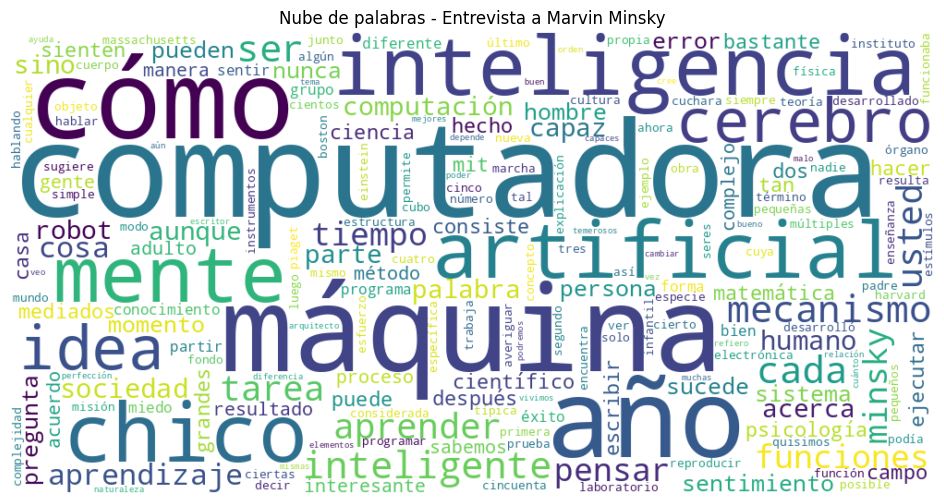

In [4]:
palabras_limpias = [
    palabra
    for palabra in palabras
    if palabra not in stop_words and len(palabra) > 2
]

texto_limpio = " ".join(palabras_limpias)

print("Cantidad de palabras antes de limpiar:", len(palabras))
print("Cantidad de palabras después de limpiar:", len(palabras_limpias))

if len(palabras_limpias) == 0:
    raise ValueError("No quedaron palabras después de la limpieza.")

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    collocations=False
).generate(texto_limpio)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Nube de palabras - Entrevista a Marvin Minsky")
plt.show()

Con la nube de palabras puedo observar de manera visual qué términos tienen mayor presencia en la entrevista una vez eliminadas las palabras de uso frecuente.

### 2.3 - Representación del texto

#### 2.3.1 - Limpieza, oraciones y matriz documento-vocabulario

En este punto divido el texto original en oraciones. Para este trabajo considero cada oración como un documento. Después limpio cada una y utilizo `CountVectorizer` para construir la matriz documento-vocabulario.

In [5]:
oraciones = sent_tokenize(texto, language="spanish")

oraciones_limpias = []

for oracion in oraciones:
    palabras_oracion = re.findall(
        r"\b[a-záéíóúüñ]+\b",
        oracion.lower()
    )

    palabras_oracion = [
        palabra
        for palabra in palabras_oracion
        if palabra not in stop_words and len(palabra) > 2
    ]

    if palabras_oracion:
        oraciones_limpias.append(
            " ".join(palabras_oracion)
        )

vectorizador = CountVectorizer()

matriz = vectorizador.fit_transform(
    oraciones_limpias
)

vocabulario = vectorizador.get_feature_names_out()

df_matriz = pd.DataFrame(
    matriz.toarray(),
    columns=vocabulario
)

print("Cantidad de oraciones originales:", len(oraciones))
print("Cantidad de documentos utilizados:", len(oraciones_limpias))
print("Dimensiones de la matriz:", matriz.shape)

df_matriz.head(10)

Cantidad de oraciones originales: 138
Cantidad de documentos utilizados: 136
Dimensiones de la matriz: (136, 886)


,abarca,abertura,absolutamente,acabada,acción,acerca,acercarse,acierto,acostumbrarse,actitud,...,york,ésas,ésta,éxito,íntimos,órgano,órganos,último,últimos,única
0,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,1,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


En esta matriz puedo interpretar los datos de la siguiente manera:

- cada **fila** representa una oración;
- cada **columna** representa una palabra del vocabulario;
- cada **valor** indica cuántas veces aparece esa palabra en la oración.

#### 2.3.2 - Longitud del vocabulario

En este punto calculo la cantidad de palabras diferentes que forman el vocabulario después del preprocesamiento.

In [6]:
print("Longitud del vocabulario:", len(vocabulario))

Longitud del vocabulario: 886


#### 2.3.3 - Aplicación de TF-IDF

En este punto aplico TF-IDF sobre la matriz documento-vocabulario. Esta técnica me permite asignar un peso a cada término teniendo en cuenta su frecuencia dentro de un documento y también su presencia en el conjunto total de documentos.

In [7]:
tfidf = TfidfTransformer()

matriz_tfidf = tfidf.fit_transform(matriz)

df_tfidf = pd.DataFrame(
    matriz_tfidf.toarray(),
    columns=vocabulario
)

print("Cantidad de documentos:", matriz_tfidf.shape[0])
print("Cantidad de términos del vocabulario:", matriz_tfidf.shape[1])
print("Tamaño de la matriz TF-IDF:", matriz_tfidf.shape)

df_tfidf.head(10)

Cantidad de documentos: 136
Cantidad de términos del vocabulario: 886
Tamaño de la matriz TF-IDF: (136, 886)


,abarca,abertura,absolutamente,acabada,acción,acerca,acercarse,acierto,acostumbrarse,actitud,...,york,ésas,ésta,éxito,íntimos,órgano,órganos,último,últimos,única
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.276138,0.0,0.0,0.0,0.0,0.0,0.0,0.276138,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0


### Formato de la matriz resultante

La matriz TF-IDF mantiene la misma estructura general que la matriz documento-vocabulario:

- las filas representan los documentos, que en este caso son las oraciones;
- las columnas representan las palabras del vocabulario;
- cada celda contiene el peso TF-IDF de una palabra dentro de una oración.

De esta manera, el tamaño final de la matriz queda determinado por la cantidad de oraciones utilizadas y la cantidad de términos del vocabulario.

# Conclusiones

Como conclusión, en este trabajo realicé un proceso completo de web scraping y preprocesamiento de texto a partir de una entrevista en español a Marvin Minsky.

Primero obtuve el contenido directamente desde una página web. Después identifiqué y eliminé las stop words, limpié el texto y generé una nube de palabras para observar los términos con mayor presencia.

Luego dividí el texto en oraciones y tomé cada una como un documento. A partir de eso construí una matriz documento-vocabulario y calculé la longitud del vocabulario.

Finalmente apliqué TF-IDF para obtener una representación numérica que tiene en cuenta no sólo la frecuencia de las palabras, sino también su importancia relativa dentro de cada documento.

Lo que más me interesó del trabajo fue ver cómo un texto en lenguaje natural puede transformarse paso a paso en una representación numérica que después puede utilizarse para otros análisis de procesamiento del lenguaje.